<a href="https://colab.research.google.com/github/njones61/ce544/blob/main/docs/unit2/10_reliability/files/reliability_calc_KEY.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Reliability Calculations

In [1]:
# Import packages
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
# Upload CSV file
from google.colab import files
uploaded = files.upload()

# get name of uploaded file
csv_file_name = list(uploaded.keys())[0]

# import csv to dataframe
df = pd.read_csv(csv_file_name)

In [3]:
df.head()

,Depth,Test,Su [tsf]
0,10.5,UU,0.25
1,10.5,UC,0.22
2,11.5,UU,0.23
3,11.5,UC,0.25
4,14.0,UU,0.20


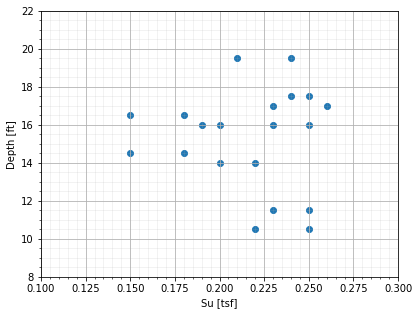

In [4]:
# Make a scatter plot of Depth values vs Su [tsf], plot depths in descending order
plt.scatter(df['Su [tsf]'], df['Depth'])
plt.xlabel('Su [tsf]')
plt.ylabel('Depth [ft]')
plt.gca().invert_yaxis()
plt.xlim(0.1, 0.3)
plt.ylim(8, 22)
plt.grid(True, which='both')
plt.minorticks_on()
plt.grid(which='minor', alpha=0.2)
plt.show()

## 1) Calculate standard deviation, coefficient of variation

In [5]:
# Calculate stddev, mean, COV of Su
stdev = df['Su [tsf]'].std()
mean = df['Su [tsf]'].mean()
cov = stdev / mean
print(f"Standard deviation: {stdev:.4f} tsf")
print(f"Mean: {mean:.4f} tsf")
print(f"Coefficient of variation: {cov:.1%}")

Standard deviation: 0.0331 tsf
Mean: 0.2165 tsf
Coefficient of variation: 15.3%


## 2) Standard deviation from the range: the 3-sigma and N-sigma rules

In [6]:
# The highest and lowest of the 20 values
su_max = df['Su [tsf]'].max()
su_min = df['Su [tsf]'].min()
print(f"Highest: {su_max:.2f} tsf, lowest: {su_min:.2f} tsf")

Highest: 0.26 tsf, lowest: 0.15 tsf


In [7]:
# 3-sigma rule: the range divided by 6
stdev_6 = (su_max - su_min) / 6
print(f"Standard deviation: {stdev_6:.4f} tsf")

Standard deviation: 0.0183 tsf


In [8]:
# N-sigma rule with N = 4: the range divided by 4
stdev_4 = (su_max - su_min) / 4
print(f"Standard deviation: {stdev_4:.4f} tsf")

Standard deviation: 0.0275 tsf


## 3) Probability of failure from F_MLV = 1.17 and COV_F = 16%

In [9]:
# Calculate the lognormal reliability index (beta_LN)
Fmlv = 1.17
COVf = 0.16
bln = np.log(Fmlv / np.sqrt(1 + COVf**2)) / np.sqrt(np.log(1 + COVf**2))
print(f"Lognormal reliability index: {bln:.3f}")

Lognormal reliability index: 0.908


In [10]:
# Calculate reliability and probability of failure
from statistics import NormalDist
reliability = NormalDist().cdf(bln)
print(f"Reliability: {reliability:.1%}")
prob_fail = 1 - reliability
print(f"Probability of failure: {prob_fail:.1%}")

Reliability: 81.8%
Probability of failure: 18.2%
